# Laboratorio 7 — Algoritmo neurogenético: Forty Soybean Cultivars
**Kevin Osmar Valdez Meza — 1288703**

**Objetivo de la práctica:** proponer una arquitectura de red neuronal (MLP feedforward entrenada con backpropagation/Adam) y optimizar sus parámetros con un algoritmo genético.

**Objetivo del dataset:** predecir el rendimiento de grano **GY (kg/ha)** de 40 cultivares de soya a partir de características medidas en la planta. En el Laboratorio 4 este fue el caso **sin una solución conveniente** (R² = 0.15), por eso se eligió para ver si la optimización genética encuentra una mejor red.

Flujo del notebook: (1) análisis exploratorio → (2) red base del Laboratorio 4 → (3) algoritmo genético → (4) red optimizada → (5) comparación.

> Todos los parámetros editables (población, generaciones, mutación, espacio de búsqueda, red base) están en `configuracion.py`.

In [1]:
import json, random
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, KFold, cross_val_score
import configuracion as cfg
from redes import *
from GAneuro import GA
import graficas as gr
pd.set_option('display.float_format', '{:.4f}'.format)
pd.set_option('display.max_columns', 20)
print('Parametros del GA:', cfg.GA_PARAMS)

Parametros del GA: {'num_inv': 24, 'max_generaciones': 20, 'torneo': 3, 'prob_mutacion': 0.15, 'por_remplazo': 0.3, 'folds': 3}


## 1. Análisis exploratorio de los datos

In [2]:
df, X, y, grupos = cargar_soybean()
print('Registros:', df.shape[0], '| Columnas:', df.shape[1], '| Nulos:', int(df.isna().sum().sum()))
print('Cultivares:', df.Cultivar.nunique(), '| Temporadas:', df.Season.nunique(), '| Repeticiones:', df.Repetition.nunique())
display(df.head(8))
df.describe().T

Registros: 320 | Columnas: 11 | Nulos: 0
Cultivares: 40 | Temporadas: 2 | Repeticiones: 4


,Season,Cultivar,Repetition,PH,IFP,NLP,NGP,NGL,NS,MHG,GY
0,1,NEO 760 CE,1,58.8000,15.2000,98.2000,177.8000,1.8100,5.2000,152.2000,3232.8200
1,1,NEO 760 CE,2,58.6000,13.4000,102.0000,195.0000,1.8500,7.2000,141.6900,3517.3600
2,1,NEO 760 CE,3,63.4000,17.2000,100.4000,203.0000,2.0200,6.8000,148.8100,3391.4600
3,1,NEO 760 CE,4,60.2700,15.2700,100.2000,191.9300,1.8900,6.4000,148.5000,3312.5800
4,1,MANU IPRO,1,81.2000,18.0000,98.8000,173.0000,1.7500,7.4000,145.5900,3230.9900
5,1,MANU IPRO,2,75.8000,20.8000,69.2000,128.0000,1.8500,7.2000,154.8700,3374.8000
6,1,MANU IPRO,3,84.4000,15.8000,95.4000,161.8000,1.7000,6.8000,150.2300,3182.7600
7,1,MANU IPRO,4,80.4700,18.2000,87.8000,154.2700,1.7700,7.1300,149.9000,3165.7200


,count,mean,std,min,25%,50%,75%,max
Season,320.0000,1.5000,0.5008,1.0000,1.0000,1.5000,2.0000,2.0000
Repetition,320.0000,2.5000,1.1198,1.0000,1.7500,2.5000,3.2500,4.0000
PH,320.0000,68.3868,8.9582,47.6000,62.9500,67.2000,74.3475,94.8000
IFP,320.0000,15.4650,3.0243,7.2000,13.6000,15.6000,17.3300,26.4000
NLP,320.0000,59.0883,20.0682,20.2000,44.3500,54.5000,71.2200,123.0000
NGP,320.0000,135.0858,60.4945,47.8000,95.0525,123.0000,161.3500,683.4000
NGL,320.0000,2.2908,0.8401,0.9400,2.0000,2.2800,2.4800,14.8600
NS,320.0000,4.0717,1.4745,0.4000,3.0000,3.8000,5.0000,9.0000
MHG,320.0000,168.3223,19.6256,127.0600,153.8450,166.1500,183.1825,216.0000
GY,320.0000,3418.5538,503.0036,1538.2300,3126.6116,3397.2767,3708.2629,4930.0000


### ¿Qué es y qué variables tiene?
Experimento agronómico de Brasil (UCI Machine Learning Repository): 40 cultivares de soya sembrados en **2 temporadas** con **4 repeticiones** cada una (40 × 2 × 4 = 320 parcelas).

| Variable | Significado | Tipo |
|---|---|---|
| `Season` | temporada de cosecha (1 o 2) | categórica |
| `Cultivar` | variedad de soya (40 distintas) | categórica |
| `Repetition` | número de repetición (1–4) | identificador, no se usa |
| `PH` | altura de la planta (cm) | numérica |
| `IFP` | altura de inserción de la primera vaina (cm) | numérica |
| `NLP` | número de tallos/ramas por planta | numérica |
| `NGP` | número de vainas por planta | numérica |
| `NGL` | número de granos por vaina | numérica |
| `NS` | número de semillas | numérica |
| `MHG` | peso de mil semillas (g) | numérica |
| **`GY`** | **rendimiento de grano (kg/ha) — salida** | numérica |

En el Lab 4 solo se usaron las 7 variables numéricas; `Cultivar` se excluyó por ser categórica. Aquí se codifica con *one-hot* (40 columnas 0/1) y se deja que el GA decida si conviene usarla.

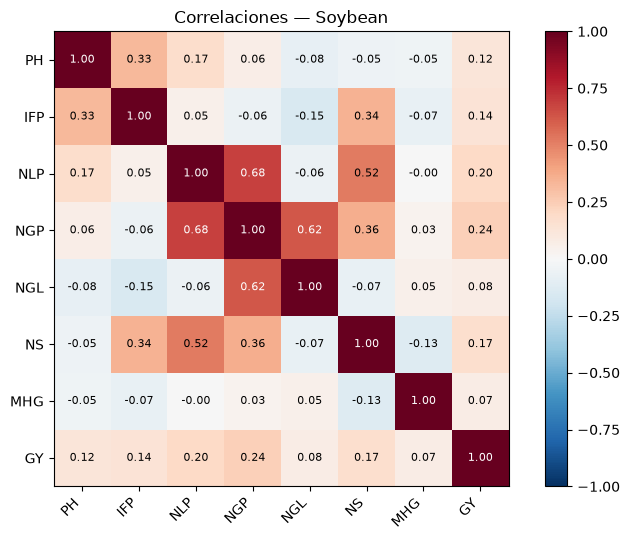

,correlación con GY
NGP,0.2389
NLP,0.1987
NS,0.1670
IFP,0.1391
PH,0.1233
NGL,0.0774
MHG,0.0746


In [3]:
num = ['PH', 'IFP', 'NLP', 'NGP', 'NGL', 'NS', 'MHG', 'GY']
corr = gr.mapa_correlacion(df, num, 'Correlaciones — Soybean', 'soybean_correlacion')
corr['GY'].drop('GY').sort_values(ascending=False).to_frame('correlación con GY')

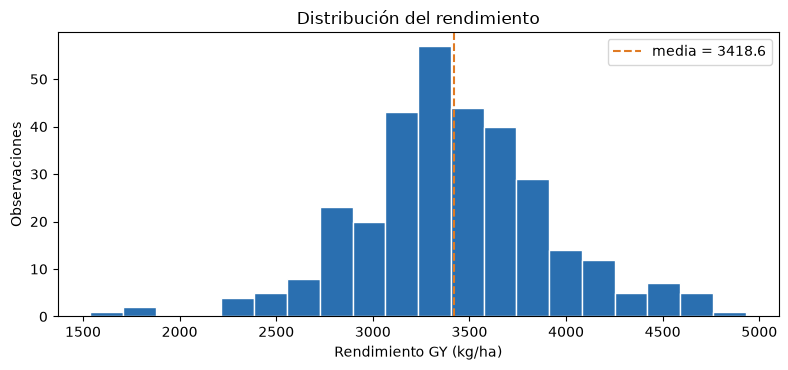

GY: media=3418.6, desviación=503.0, min=1538.2, max=4930.0 kg/ha


In [4]:
gr.histograma(df.GY, 'Rendimiento GY (kg/ha)', 'Distribución del rendimiento', 'soybean_histograma')
print(f"GY: media={df.GY.mean():.1f}, desviación={df.GY.std():.1f}, min={df.GY.min():.1f}, max={df.GY.max():.1f} kg/ha")

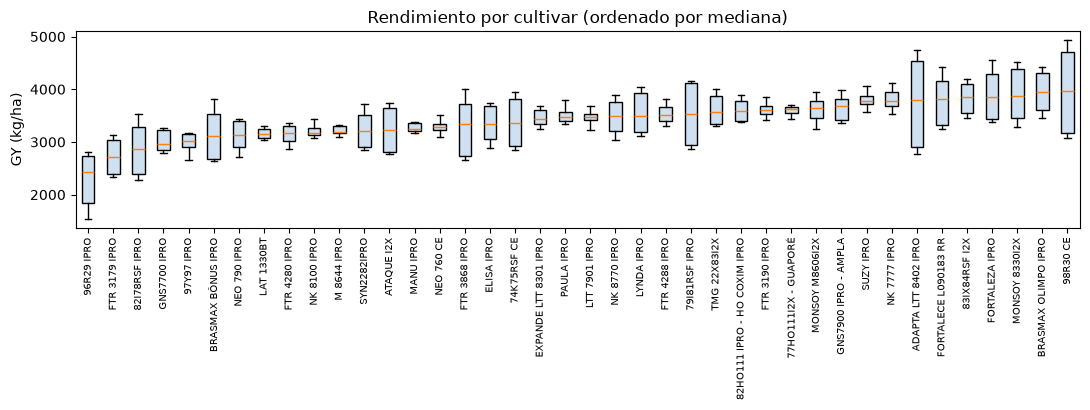

Proporción de la varianza de GY explicada solo por el cultivar (eta^2) = 0.494
            mean      std
Season                   
1      3428.4524 639.0366
2      3408.6552 314.7245


In [5]:
gr.cajas_por_grupo(df, 'Cultivar', 'GY', 'GY (kg/ha)', 'Rendimiento por cultivar (ordenado por mediana)', 'soybean_cultivar')
eta2 = df.groupby('Cultivar').GY.transform('mean').var() / df.GY.var()
print(f'Proporción de la varianza de GY explicada solo por el cultivar (eta^2) = {eta2:.3f}')
print(df.groupby('Season').GY.agg(['mean', 'std']))

**Observaciones del análisis:**
- No hay valores nulos; hay algunos valores extremos (p. ej. `NGP` = 683 y `NGL` = 14.9, muy fuera del rango típico).
- Ninguna variable numérica tiene correlación fuerte con `GY` (todas < 0.25). Por eso la red del Lab 4 solo explicaba ~15 % de la variación.
- En cambio, el **cultivar** explica una parte grande de la varianza del rendimiento (eta² de la celda anterior): la variedad genética es información que el Lab 4 dejó fuera.
- La temporada casi no cambia la media de GY.

## 2. Red neuronal base (Laboratorio 4)
Se reproduce exactamente la red del Laboratorio 4 con la misma división **60 % entrenamiento / 40 % prueba** (`random_state=42`). Se guardan la métrica de rendimiento (R², R, MAE, RMSE) y la pérdida: `loss_final` es la pérdida de entrenamiento del último epoch (MSE escalado) y `MSE` es la pérdida total en el conjunto de prueba en unidades reales.

In [6]:
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=cfg.TEST_SIZE, random_state=cfg.SEMILLA_RED)
print('Entrenamiento:', len(Xtr), '| Prueba:', len(Xte))
base = cfg.BASE_SOYBEAN
mod_base, pred_base, m_base = entrenar_y_evaluar(base, grupos, Xtr, ytr, Xte, yte)
kf = KFold(cfg.GA_PARAMS['folds'], shuffle=True, random_state=cfg.SEMILLA_RED)
cv_base = cross_val_score(crear_red(base), Xtr[columnas(base, grupos)], ytr, cv=kf, scoring='r2').mean()
print('Red base:', describir(base, grupos))
print('Variables:', base['variables'])
print(f'Aptitud de la red base (R2 validacion cruzada en entrenamiento) = {cv_base:.4f}')
pd.Series(m_base, name='Red base').to_frame()

Entrenamiento: 192 | Prueba: 128


Red base: 7-64-32-16-1 | relu | lr=0.001 | alpha=0.0001 | batch=auto
Variables: ['PH', 'IFP', 'NLP', 'NGP', 'NGL', 'NS', 'MHG']
Aptitud de la red base (R2 validacion cruzada en entrenamiento) = -0.0339


,Red base
R2,0.1527
R,0.4085
MAE,353.9225
RMSE,461.2967
MSE,212794.6380
loss_final,0.0347
epocas,242.0000
parametros,3137.0000


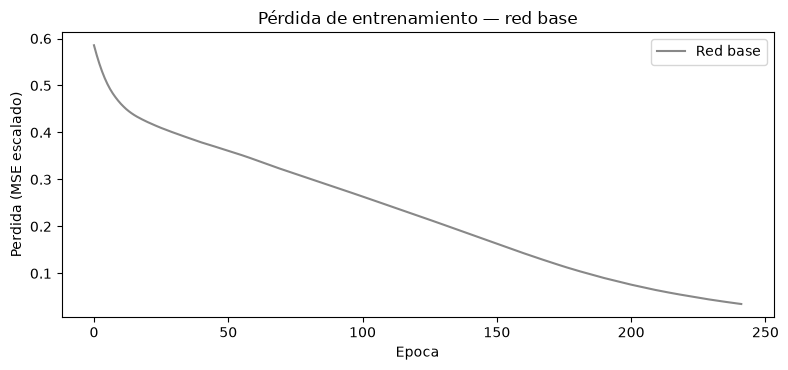

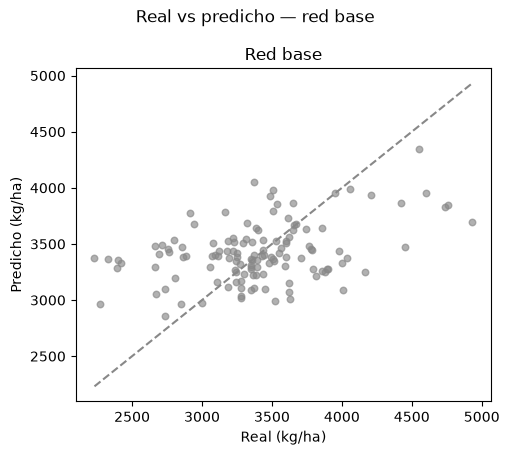

In [7]:
gr.curva_perdida([('Red base', mod_base.regressor_['nn'].loss_curve_, gr.GRIS)], 'Pérdida de entrenamiento — red base', 'soybean_perdida_base')
gr.real_vs_predicho(yte.values, [('Red base', pred_base, gr.GRIS)], 'kg/ha', 'Real vs predicho — red base', 'soybean_real_pred_base')

## 3. Algoritmo genético
Se reutiliza la estructura de los laboratorios 5 y 6: cromosoma, aptitud, selección por **torneo de 3**, **cruce de un punto**, mutación y **elitismo**. La diferencia es que cada cromosoma ahora representa una red neuronal completa.

**Cromosoma (genes enteros):** cada gen guarda el índice de una opción. Los primeros 8 genes describen la red (número de capas, neuronas por capa, activación, tasa de aprendizaje, regularización L2 `alpha` y tamaño de lote) y los siguientes son bits 0/1 que indican si se usa cada variable de entrada.

**Aptitud:** R² promedio de validación cruzada de 3 pliegues, calculado **solo con el 60 % de entrenamiento**. El 40 % de prueba no se toca durante la búsqueda, así la comparación final es justa. Si un cromosoma no usa ninguna variable recibe aptitud −1.

In [8]:
nombres, opciones = genes_del_problema(grupos)
valores = [str(v) for v in cfg.ESPACIO_RED.values()] + ['0 = no usar, 1 = usar'] * len(grupos)
pd.DataFrame({'gen': range(1, len(nombres) + 1), 'nombre': nombres, 'n_opciones': opciones, 'valores': valores})

,gen,nombre,n_opciones,valores
0,1,capas,3,"[1, 2, 3]"
1,2,neuronas1,6,"[4, 8, 16, 32, 64, 128]"
2,3,neuronas2,6,"[4, 8, 16, 32, 64, 128]"
3,4,neuronas3,6,"[4, 8, 16, 32, 64, 128]"
4,5,activacion,3,"['relu', 'tanh', 'logistic']"
5,6,tasa_aprendizaje,6,"[0.0001, 0.0003, 0.001, 0.003, 0.01, 0.03]"
6,7,alpha,8,"[1e-05, 0.0001, 0.001, 0.01, 0.1, 1.0, 3.0, 10.0]"
7,8,batch,4,"[16, 32, 64, 128]"
8,9,usar_PH,2,"0 = no usar, 1 = usar"
9,10,usar_IFP,2,"0 = no usar, 1 = usar"


In [9]:
random.seed(cfg.SEMILLA)
ga = GA(Xtr, ytr, grupos, **cfg.GA_PARAMS)
mejor, historial = ga.buscar_solucion(cfg.GA_PARAMS['max_generaciones'])
print('\nRedes distintas entrenadas y evaluadas:', len(ga.evaluar.cache))
print('Mejor cromosoma:', mejor.cadena(), '| aptitud =', round(mejor.score, 4))

[00] mejor R2_cv=0.2872 | promedio=0.0011 | 43-32-1 | relu | lr=0.0003 | alpha=1.0 | batch=64 | 31.9s


[01] mejor R2_cv=0.3882 | promedio=0.1362 | 45-64-4-1 | relu | lr=0.0003 | alpha=1.0 | batch=64 | 14.7s


[02] mejor R2_cv=0.4493 | promedio=0.1815 | 45-64-128-1 | relu | lr=0.0003 | alpha=1.0 | batch=16 | 14.6s


[03] mejor R2_cv=0.4493 | promedio=0.1721 | 45-64-128-1 | relu | lr=0.0003 | alpha=1.0 | batch=16 | 22.6s


[04] mejor R2_cv=0.4844 | promedio=0.2393 | 46-64-128-1 | relu | lr=0.0003 | alpha=1.0 | batch=16 | 16.8s


[05] mejor R2_cv=0.5065 | promedio=0.3077 | 47-32-1 | relu | lr=0.03 | alpha=1.0 | batch=128 | 15.0s


... (11 outputs left out)

[17] mejor R2_cv=0.5963 | promedio=0.3759 | 45-32-16-1 | relu | lr=0.03 | alpha=1.0 | batch=128 | 7.6s


[18] mejor R2_cv=0.5963 | promedio=0.3710 | 45-32-16-1 | relu | lr=0.03 | alpha=1.0 | batch=128 | 8.3s


[19] mejor R2_cv=0.5963 | promedio=0.3424 | 45-32-16-1 | relu | lr=0.03 | alpha=1.0 | batch=128 | 4.2s


[20] mejor R2_cv=0.5963 | promedio=0.2976 | 45-32-16-1 | relu | lr=0.03 | alpha=1.0 | batch=128 | 3.4s

Redes distintas entrenadas y evaluadas: 352
Mejor cromosoma: 1-3-2-3-0-5-5-3-0-1-1-0-0-1-1-1-1 | aptitud = 0.5963


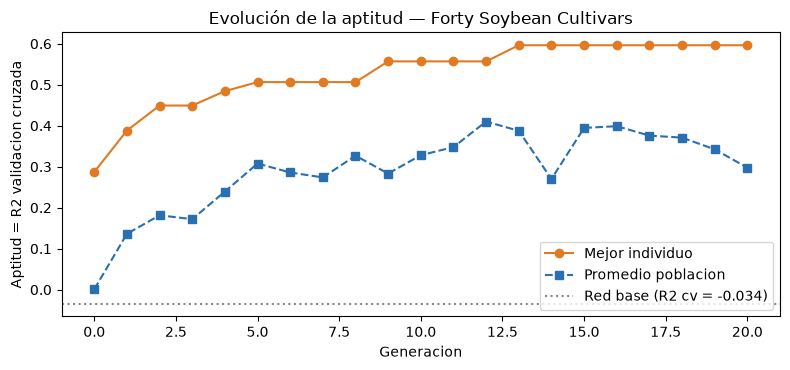

,generacion,mejor,promedio,cromosoma,red
0,0,0.2872,0.0011,0-3-0-3-0-1-5-2-1-1-1-0-0-0-0-1-0,43-32-1 | relu | lr=0.0003 | alpha=1.0 | batch=64
1,1,0.3882,0.1362,1-4-0-3-0-1-5-2-1-1-1-0-0-0-1-1-1,45-64-4-1 | relu | lr=0.0003 | alpha=1.0 | bat...
2,2,0.4493,0.1815,1-4-5-2-0-1-5-0-1-1-1-0-0-0-1-1-1,45-64-128-1 | relu | lr=0.0003 | alpha=1.0 | b...
3,3,0.4493,0.1721,1-4-5-2-0-1-5-0-1-1-1-0-0-0-1-1-1,45-64-128-1 | relu | lr=0.0003 | alpha=1.0 | b...
4,4,0.4844,0.2393,1-4-5-2-0-1-5-0-1-1-0-1-1-1-0-1-1,46-64-128-1 | relu | lr=0.0003 | alpha=1.0 | b...
5,5,0.5065,0.3077,0-3-0-3-0-5-5-3-1-1-1-0-1-1-1-1-1,47-32-1 | relu | lr=0.03 | alpha=1.0 | batch=128
6,6,0.5065,0.2860,0-3-0-3-0-5-5-3-1-1-1-0-1-1-1-1-1,47-32-1 | relu | lr=0.03 | alpha=1.0 | batch=128
7,7,0.5065,0.2739,0-3-0-3-0-5-5-3-1-1-1-0-1-1-1-1-1,47-32-1 | relu | lr=0.03 | alpha=1.0 | batch=128
8,8,0.5065,0.3269,0-3-0-3-0-5-5-3-1-1-1-0-1-1-1-1-1,47-32-1 | relu | lr=0.03 | alpha=1.0 | batch=128
9,9,0.5570,0.2833,0-3-5-3-0-5-5-3-1-1-1-0-1-1-0-1-1,46-32-1 | relu | lr=0.03 | alpha=1.0 | batch=128


In [10]:
hist = pd.DataFrame(historial)
gr.evolucion_ga(historial, 'Evolución de la aptitud — Forty Soybean Cultivars', 'soybean_evolucion_ga', base_cv=cv_base)
hist

In [11]:
# Cinco mejores redes distintas de la ultima generacion
vistos, filas = set(), []
for crom in sorted(ga.poblacion, key=lambda c: c.score, reverse=True):
    if crom.clave() in vistos: continue
    vistos.add(crom.clave()); p = decodificar(crom.genes, grupos)
    filas.append({'cromosoma': crom.cadena(), 'R2_cv': crom.score, 'red': describir(p, grupos), 'variables': ', '.join(p['variables'])})
    if len(filas) == 5: break
pd.DataFrame(filas)

,cromosoma,R2_cv,red,variables
0,1-3-2-3-0-5-5-3-0-1-1-0-0-1-1-1-1,0.5963,45-32-16-1 | relu | lr=0.03 | alpha=1.0 | batc...,"IFP, NLP, NS, MHG, Cultivar, Season"
1,0-3-5-3-0-5-5-3-1-1-1-0-1-1-0-1-1,0.5570,46-32-1 | relu | lr=0.03 | alpha=1.0 | batch=128,"PH, IFP, NLP, NGL, NS, Cultivar, Season"
2,0-3-2-3-0-5-5-3-0-1-1-0-0-0-0-1-1,0.5503,43-32-1 | relu | lr=0.03 | alpha=1.0 | batch=128,"IFP, NLP, Cultivar, Season"
3,1-2-2-3-0-5-5-3-0-1-1-0-1-1-1-1-1,0.5498,46-16-16-1 | relu | lr=0.03 | alpha=1.0 | batc...,"IFP, NLP, NGL, NS, MHG, Cultivar, Season"
4,1-3-2-3-0-5-5-2-0-1-1-0-0-0-0-1-1,0.4944,43-32-16-1 | relu | lr=0.03 | alpha=1.0 | batc...,"IFP, NLP, Cultivar, Season"


## 4. Red neuronal con parámetros optimizados
Se decodifica el mejor cromosoma, se entrena con todo el 60 % y se evalúa una sola vez con el 40 % de prueba.

In [12]:
opt = decodificar(mejor.genes, grupos)
mod_opt, pred_opt, m_opt = entrenar_y_evaluar(opt, grupos, Xtr, ytr, Xte, yte)
print('Red optimizada:', describir(opt, grupos))
print('Variables elegidas por el GA:', opt['variables'])
print('Variables descartadas:', [g for g in grupos if g not in opt['variables']])
pd.Series(m_opt, name='Red GA').to_frame()

Red optimizada: 45-32-16-1 | relu | lr=0.03 | alpha=1.0 | batch=128
Variables elegidas por el GA: ['IFP', 'NLP', 'NS', 'MHG', 'Cultivar', 'Season']
Variables descartadas: ['PH', 'NGP', 'NGL']


,Red GA
R2,0.7184
R,0.8615
MAE,202.6424
RMSE,265.9216
MSE,70714.2985
loss_final,0.0600
epocas,210.0000
parametros,2017.0000


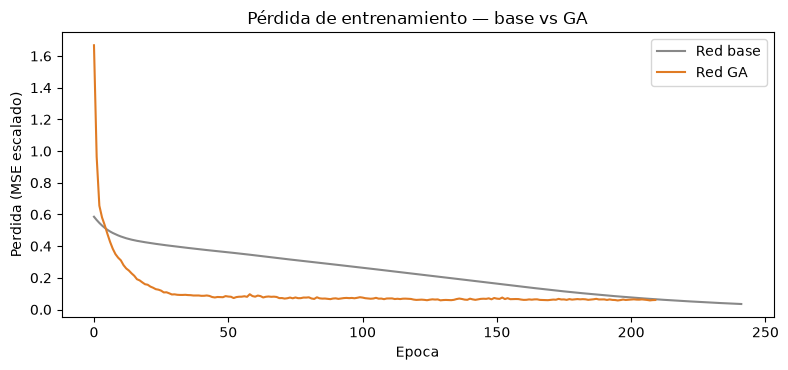

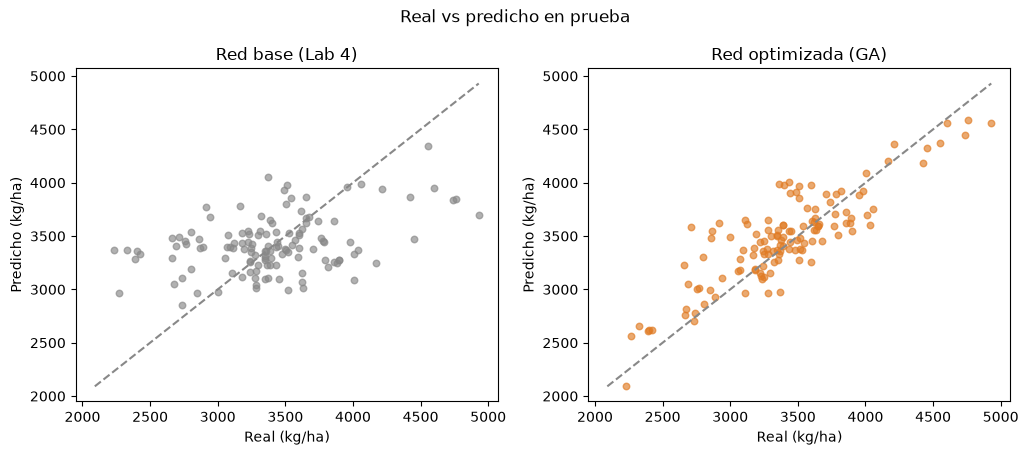

In [13]:
gr.curva_perdida([('Red base', mod_base.regressor_['nn'].loss_curve_, gr.GRIS), ('Red GA', mod_opt.regressor_['nn'].loss_curve_, gr.NARANJA)], 'Pérdida de entrenamiento — base vs GA', 'soybean_perdida_comparacion')
gr.real_vs_predicho(yte.values, [('Red base (Lab 4)', pred_base, gr.GRIS), ('Red optimizada (GA)', pred_opt, gr.NARANJA)], 'kg/ha', 'Real vs predicho en prueba', 'soybean_real_pred_comparacion')

## 5. Comparación entre las dos propuestas
Para separar el efecto de **qué variables se usan** del efecto de **cómo es la red**, se agrega un modelo intermedio: la arquitectura base del Lab 4 pero con las variables que eligió el GA.

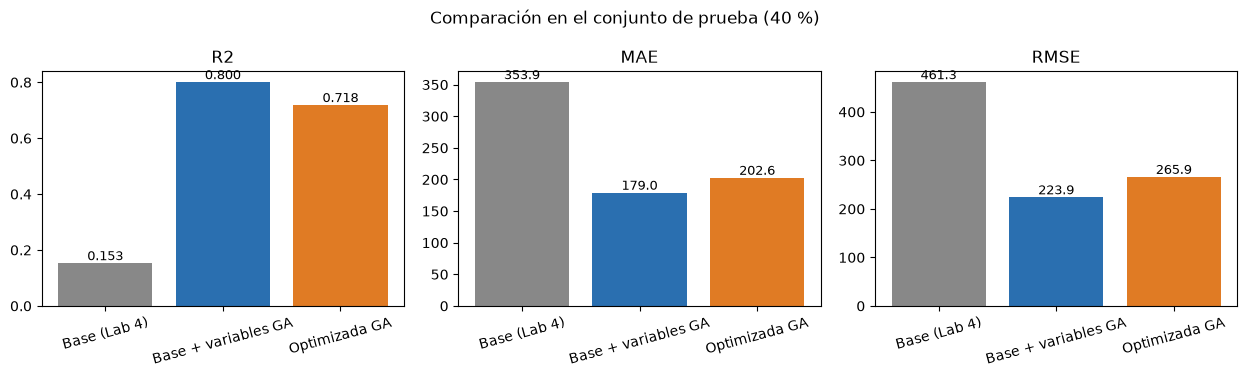

,R2,R,MAE,RMSE,MSE,loss_final,epocas,parametros,arquitectura
Base (Lab 4),0.1527,0.4085,353.9225,461.2967,212794.6380,0.0347,242,3137,7-64-32-16-1 | relu | lr=0.001 | alpha=0.0001 ...
Base + variables GA,0.8004,0.8955,178.9765,223.9131,50137.0954,0.0034,207,5569,45-64-32-16-1 | relu | lr=0.001 | alpha=0.0001...
Optimizada GA,0.7184,0.8615,202.6424,265.9216,70714.2985,0.0600,210,2017,45-32-16-1 | relu | lr=0.03 | alpha=1.0 | batc...


In [14]:
intermedia = dict(base, variables=opt['variables'])
_, _, m_int = entrenar_y_evaluar(intermedia, grupos, Xtr, ytr, Xte, yte)
tabla = pd.DataFrame([m_base, m_int, m_opt], index=['Base (Lab 4)', 'Base + variables GA', 'Optimizada GA'])
tabla['arquitectura'] = [describir(base, grupos), describir(intermedia, grupos), describir(opt, grupos)]
gr.barras_comparacion(tabla, ['R2', 'MAE', 'RMSE'], 'Comparación en el conjunto de prueba (40 %)', 'soybean_comparacion')
tabla

### Robustez
Un solo entrenamiento puede salir bien o mal por suerte en la inicialización de pesos. Se repite el entrenamiento con 10 semillas distintas (misma división de datos).

In [15]:
rob_base = robustez(base, grupos, Xtr, ytr, Xte, yte)
rob_int = robustez(intermedia, grupos, Xtr, ytr, Xte, yte)
rob_opt = robustez(opt, grupos, Xtr, ytr, Xte, yte)
rob = pd.DataFrame({'Base R2': rob_base.R2, 'Base+vars R2': rob_int.R2, 'GA R2': rob_opt.R2, 'Base MAE': rob_base.MAE, 'Base+vars MAE': rob_int.MAE, 'GA MAE': rob_opt.MAE})
display(rob.describe().loc[['mean', 'std', 'min', 'max']])
mejora = (m_base['MAE'] - m_opt['MAE']) / m_base['MAE'] * 100
print(f"R2: {m_base['R2']:.4f} -> {m_opt['R2']:.4f} | MAE: {m_base['MAE']:.2f} -> {m_opt['MAE']:.2f} kg/ha ({mejora:.1f} % menos error)")

,Base R2,Base+vars R2,GA R2,Base MAE,Base+vars MAE,GA MAE
mean,0.0735,0.6677,0.7304,367.8194,201.5396,186.7605
std,0.0579,0.1211,0.0808,14.5893,27.7842,22.5741
min,0.0177,0.5189,0.6072,330.4915,149.5903,152.3722
max,0.2170,0.8517,0.8372,381.3970,234.3080,223.3953


R2: 0.1527 -> 0.7184 | MAE: 353.92 -> 202.64 kg/ha (42.7 % menos error)


In [16]:
res = {'dataset': 'Forty Soybean Cultivars', 'n': int(len(df)), 'n_train': int(len(Xtr)), 'n_test': int(len(Xte)),
       'base': {**m_base, 'red': describir(base, grupos), 'variables': base['variables'], 'cv': float(cv_base)},
       'intermedia': {**m_int, 'red': describir(intermedia, grupos)},
       'optimizada': {**m_opt, 'red': describir(opt, grupos), 'variables': opt['variables'], 'cv': float(mejor.score), 'cromosoma': mejor.cadena()},
       'robustez': {'base_mean': float(rob_base.R2.mean()), 'base_std': float(rob_base.R2.std()), 'int_mean': float(rob_int.R2.mean()), 'int_std': float(rob_int.R2.std()), 'opt_mean': float(rob_opt.R2.mean()), 'opt_std': float(rob_opt.R2.std()),
                    'base_mae': float(rob_base.MAE.mean()), 'int_mae': float(rob_int.MAE.mean()), 'opt_mae': float(rob_opt.MAE.mean())},
       'historial': historial, 'redes_evaluadas': len(ga.evaluar.cache), 'ga': cfg.GA_PARAMS}
json.dump(res, open('resultados_soybean.json', 'w', encoding='utf-8'), indent=2, ensure_ascii=False)
print('Resultados guardados en resultados_soybean.json')

Resultados guardados en resultados_soybean.json


## Conclusión
En una sola corrida (semilla 42) la red optimizada obtuvo R² = 0.718 y MAE = 202.6 kg/ha. El modelo intermedio (la arquitectura base, pero con las variables elegidas por el GA) obtuvo 0.800 en esa corrida, aunque al repetir con 10 semillas su promedio baja a 0.668 ± 0.121, mientras que la red del GA promedia 0.730 ± 0.081 y la base solo 0.073 ± 0.058. El MAE promedio pasa de 368 kg/ha (base) a 202 kg/ha (intermedio) y 187 kg/ha (GA).

La conclusión es que la mayor parte de la mejora viene de la selección de variables que hizo el GA (incluir el cultivar y la temporada), y los hiperparámetros optimizados agregan precisión y sobre todo estabilidad: la red del GA varía menos entre semillas que el modelo intermedio. El problema del Laboratorio 4 no era tanto la arquitectura, sino que faltaba la información de la variedad.

Comparar con una sola corrida puede llevar a conclusiones opuestas: con la semilla 42, en HydroGrowNet la red del GA parecía peor, y en Soybean el modelo intermedio parecía mejor. Al repetir con 10 semillas ambas conclusiones se invierten. Por eso la aptitud se calculó con validación cruzada y la comparación final con varias semillas.